# Matplotlib Temelleri

Önceki derslerde veriyi tanıdın, temizledin ve grafik türlerini seçmeyi öğrendin. Bugün ilk kez **grafik üreten kod** yazıyorsun. Python'un en yaygın görselleştirme kütüphanesi olan matplotlib ile çizgi, çubuk, dağılım ve histogram grafiklerini üretecek; başlık, eksen etiketi, renk ve işaret ayarlarını öğreneceksin. Çalışma verimiz yine kahve zinciri: 5. dersten tanıdığın satış tablosu.

## 🎯 Bu Derste Ne Öğreneceğiz?

Bu dersin sonunda şunları yapabileceksin:

- matplotlib'in `pyplot` arayüzüyle çizgi, çubuk, dağılım ve histogram grafikleri üretmek
- Başlık ve eksen etiketleriyle grafiği "konuşturmak"
- Renk, çizgi tipi, işaret (marker) ve kalınlık ayarlarını yapmak
- `figsize` ve `grid` gibi düzenleme seçeneklerini kullanmak
- Grafik kodundaki yaygın hataları teşhis etmek

Bu ders, kursun 7. öğrenme çıktısının ilk yarısını karşılıyor.

## 💡 Neden Bu Konuyu Öğreniyoruz?

1. dersten beri grafiklerin **okuyucusu**ydun; artık **yazarı** oluyorsun. Üreteceğin her grafik, 1. dersin ilkeleriyle (tek mesaj, dürüst eksen, anlamlı renk) ve 2. dersin seçim kararlarıyla (soru türüne göre grafik türü) buluşacak. matplotlib bu üretimin temel aracı; 9. derste öğreneceğin seaborn bile arka planda matplotlib'i kullanır. Yani bugün öğrenilen her şey, kursın sonuna kadar geçerli.

## 🔗 Ön Bilgi

- [pandas DataFrame](05-Pandas-Dataframe.ipynb): `groupby` ile özetleme (bu derste grafiğin verisini hazırlayacağız).
- [Veri Temizleme ve Keşfedici Analiz](06-Data-Cleaning.ipynb): histogramda temiz verinin önemi.
- [Grafik Türleri ve Doğru Seçim](02-Chart-Types.ipynb): hangi durumda hangi grafik.

## 🔍 Birlikte Keşfedelim

Aşağıdaki hücre, olabilecek en küçük çizgi grafik kodunu içeriyor: altı aylık toplam satışları iki satırda çiziyor. Çalıştırmadan önce tahmin et: eksenlerde ne göreceksin? Grafiğe bakan biri "bu neymiş?" sorusuna cevap bulabilecek mi?

**Tahminin:** ...

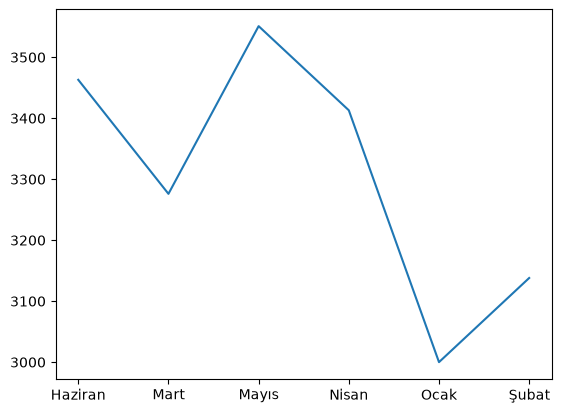

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

satis = pd.read_csv("../Data/05-coffee-sales.csv")
aylik_toplam = satis.groupby("ay")["adet"].sum()

plt.plot(aylik_toplam.index, aylik_toplam.values)
plt.show()

**Gözlem:** Bir grafik çıktı — ama kimseye bir şey anlatmıyor. Hangi aylar bunlar? Eksenlerdeki sayılar neyi ölçüyor? Bin kişi mi, fincan mı, TL mi? Eksik olan şey veri değil, **bağlam**: başlık ve eksen etiketleri. Aynı grafiği "konuşturalım":

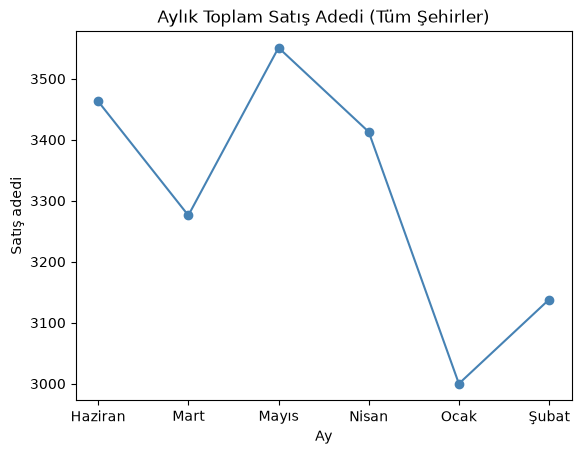

In [2]:
plt.plot(aylik_toplam.index, aylik_toplam.values, marker="o", color="steelblue")
plt.title("Aylık Toplam Satış Adedi (Tüm Şehirler)")
plt.xlabel("Ay")
plt.ylabel("Satış adedi")
plt.show()

**Gözlem:** Üç satır ekledik (marker seçimiyle birlikte dört değişiklik) ve grafik bir haber cümlesine dönüştü: "Satışlar altı ayda yaklaşık 2.900'den 3.700'e çıktı." 1. dersin "grafik = kod + tasarım kararları" cümlesini hatırla: başlık ve etiket de tasarım kararıdır ve kodun parçasıdır. Şimdi araçları tek tek tanıyalım.

## 📖 Kavramlar

**pyplot arayüzü:** `import matplotlib.pyplot as plt` ile gelen komut dizisi. `plt.plot(...)`, `plt.title(...)`, `plt.bar(...)` gibi komutlar sırayla çalışır ve tek bir aktif grafiğin üzerine eklenir; `plt.show()` grafiği görüntüler. Bu "sırayla biriktir, sonra göster" mantığı, 3. dersteki hücre mantığına benzer.

**Çizim fonksiyonları:** `plot` (çizgi), `bar` (dikey çubuk), `barh` (yatay çubuk), `scatter` (dağılım), `hist` (histogram). Hangisini seçeceğin 2. dersin karar tablosundaydı; bugün hepsini kodluyoruz.

**Etiket katmanı:** `title`, `xlabel`, `ylabel`. Grafiklerin en sık eksilen parçası budur; oysa okuyucu için en gerekli olanıdır.

**Özelleştirme parametreleri:** `color` (renk), `linestyle` (çizgi tipi), `marker` (nokta işareti), `linewidth` (kalınlık), `figsize` (grafiğin inç cinsinden boyutu), `grid` (ızgara). Hepsi çizim fonksiyonuna ya da `plt.` komutlarına argüman olarak verilir — 4. dersteki argüman kavramının grafik versiyonu.

## 🛠️ Uygulama

### 1) Çizgi grafiği özelleştirmek

Aynı grafiği farklı bir karakterle çizelim; parametrelerin her birini değiştirerek etkisini gör:

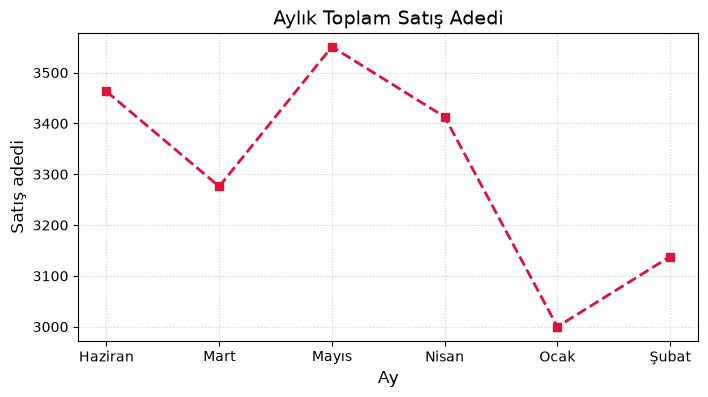

In [3]:
plt.figure(figsize=(8, 4))
plt.plot(aylik_toplam.index, aylik_toplam.values,
         color="crimson", linestyle="--", marker="s", linewidth=2)
plt.title("Aylık Toplam Satış Adedi", fontsize=14)
plt.xlabel("Ay", fontsize=12)
plt.ylabel("Satış adedi", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

Parametre sözlüğü: `color="crimson"` kırmızı tonu, `linestyle="--"` kesikli çizgi, `marker="s"` kare işaret, `linewidth=2` kalınlık, `figsize=(8, 4)` grafiğin 8×4 inç olduğu, `grid(True)` arka ızgara (`alpha=0.6` saydamlığı) demek.

### 2) Çubuk grafik: şehir karşılaştırması

"Toplam satışta şehirler nasıl sıralanıyor?" sorusu bir karşılaştırma sorusuydu; çizgi yerine çubuk seçiyoruz:

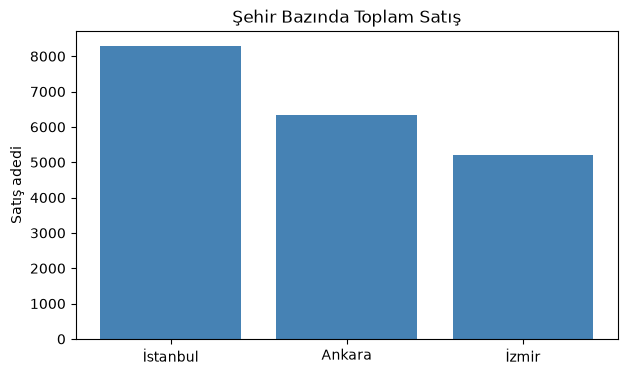

In [4]:
sehir_toplam = satis.groupby("sehir")["adet"].sum().sort_values(ascending=False)

plt.figure(figsize=(7, 4))
plt.bar(sehir_toplam.index, sehir_toplam.values, color="steelblue")
plt.title("Şehir Bazında Toplam Satış")
plt.ylabel("Satış adedi")
plt.show()

Kategori adları uzunsa yatay çubuk (`barh`) daha okunaklıdır; eksenler yer değiştirir:

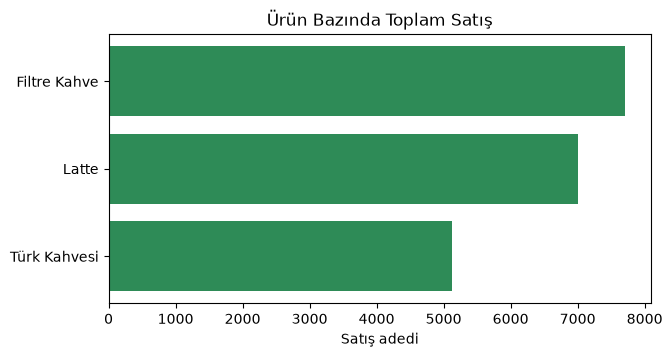

In [5]:
urun_adet = satis.groupby("urun")["adet"].sum().sort_values()

plt.figure(figsize=(7, 3.5))
plt.barh(urun_adet.index, urun_adet.values, color="seagreen")
plt.title("Ürün Bazında Toplam Satış")
plt.xlabel("Satış adedi")
plt.show()

### 3) Dağılım grafiği: iki sayısal değişkenin ilişkisi

Dağılım grafiği için iki sayısal sütun gerekir. Satış tablosunda bir ilişki sorusu soralım: "Reklam bütçesi arttıkça satış artıyor mu?" Zincirin aylık reklam bütçesi şöyle olsun:

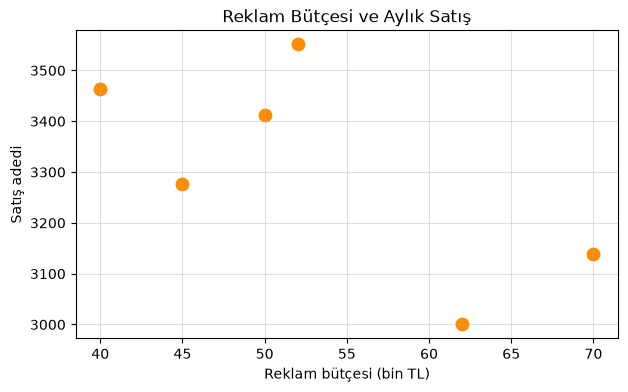

In [6]:
reklam = [40, 45, 52, 50, 62, 70]     # bin TL

plt.figure(figsize=(7, 4))
plt.scatter(reklam, aylik_toplam.values, color="darkorange", s=80)
plt.title("Reklam Bütçesi ve Aylık Satış")
plt.xlabel("Reklam bütçesi (bin TL)")
plt.ylabel("Satış adedi")
plt.grid(True, alpha=0.4)
plt.show()

**Gözlem:** Noktalar sol alttan sağ üste diziliyor: bütçe büyüdükçe satış büyümüş. İki değişken arasında pozitif bir ilişki var gibi görünüyor. (İlişkinin "neden" olduğu sonucunu tek grafikten çıkaramayız — bu uyarıyı 15. derste hikâyeleştirirken yeniden göreceğiz.) `s=80` noktaların boyutunu ayarlar.

### 4) Histogram: sipariş adetlerinin dağılımı

Satış tablosundaki 54 satırlık `adet` sütununun dağılımına bakalım:

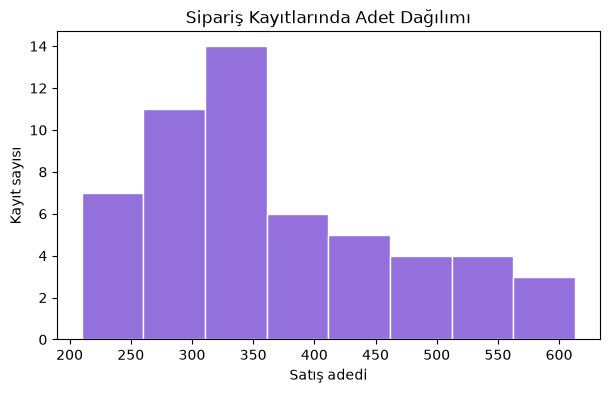

In [7]:
plt.figure(figsize=(7, 4))
plt.hist(satis["adet"], bins=8, color="mediumpurple", edgecolor="white")
plt.title("Sipariş Kayıtlarında Adet Dağılımı")
plt.xlabel("Satış adedi")
plt.ylabel("Kayıt sayısı")
plt.show()

**Gözlem:** Adetler iki kümede toplanıyor gibi: 240-330 arası (İzmir + Türk Kahvesi kayıtları) ve 380-570 arası (büyük şehir kayıtları). Histogram bize tablonun "iki farklı dünya" taşıdığını söylüyor — 6. derste öğrendiğimiz dağılım bakışının grafiğe dökülmüş hâli.

### 5) Kodu tamamla (TODO)

In [8]:
# TODO: İstanbul'un aylık satışlarını (yalnızca İstanbul satırları, ay bazında toplam)
# çizgi grafikle çiz. Başlık ve eksen etiketlerini eklemeyi unutma.

istanbul = satis[satis["sehir"] == "İstanbul"]
# istanbul_aylik = ...          <- bu satırı tamamla (groupby)
# plt.plot(...)                 <- grafiği çiz
# plt.title(...), plt.xlabel(...), plt.ylabel(...)
# plt.show()

print("Kontrol: İstanbul toplam:", istanbul["adet"].sum())

Kontrol: İstanbul toplam: 8301


Çözüm "Cevaplar" bölümünde.

## 🧪 Deneyelim ve Gözlemleyelim

**Deney 1:** `bins` sayısı histogramın ayrıntı düzeyini belirler. Aynı veriyi üç farklı `bins` değeriyle çiz; hangisi "iki küme" örüntüsünü en iyi anlatıyor?

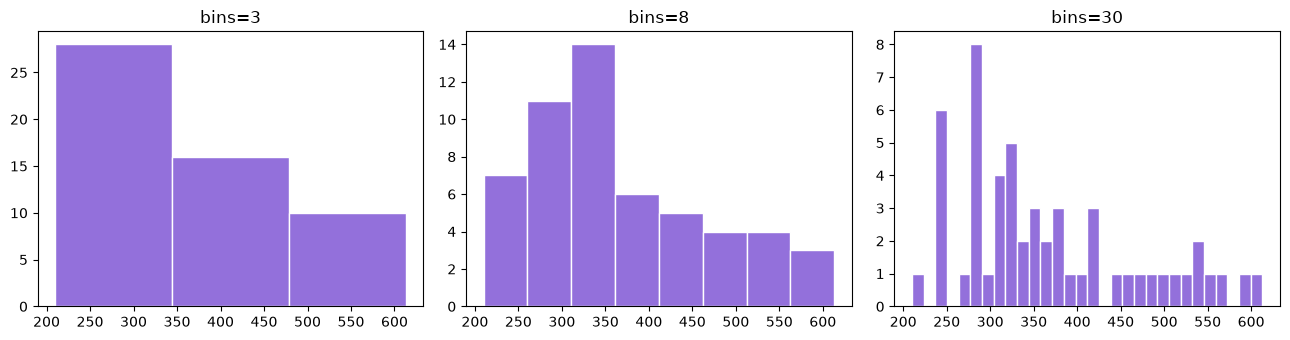

In [9]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 3.5))

ax1.hist(satis["adet"], bins=3, color="mediumpurple", edgecolor="white")
ax1.set_title("bins=3")
ax2.hist(satis["adet"], bins=8, color="mediumpurple", edgecolor="white")
ax2.set_title("bins=8")
ax3.hist(satis["adet"], bins=30, color="mediumpurple", edgecolor="white")
ax3.set_title("bins=30")

plt.tight_layout()
plt.show()

**Gözlem:** `bins=3` örüntüyü siler, `bins=30` gürültüye boğar. Doğru ayrıntı düzeyi veriye ve soruya bağlıdır; genelde birkaç değeri deneyip en anlamlı olanı seçersin. (Bu hücrede `subplots` kullandık — birden çok grafiği tek figüre yerleştirmenin yolu. 8. derste ayrıntılı işleyeceğiz.)

**Deney 2:** Uzunluk uyuşmazlığı neye yol açar? Aşağıdaki hücrede bilerek 6 aylık eksenle 5 değerlik bir liste çiziyoruz. Önce hatayı tahmin et, sonra çalıştır:

ValueError: x and y must have same first dimension, but have shapes (6,) and (5,)

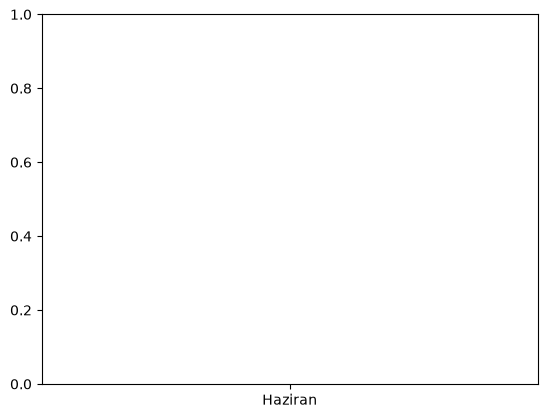

In [10]:
plt.plot(aylik_toplam.index, [100, 200, 300, 400, 500])
plt.show()

**Gözlem:** `ValueError: x and y must have same first dimension...` Her çizim fonksiyonu eksen verilerinin **eşit uzunlukta** olmasını ister; bir taraf 6, öbürü 5 değer taşıyınca matplotlib çizmeye teşebbüs etmez bile. Mesajı oku, uzunlukları `len(...)` ile karşılaştır, düzelt.

**Deney 3:** `figsize`'ı `(4, 8)` yaparak son çubuk grafiği yeniden çiz. Ne değişti? Dar-long bir grafik ne gibi izlenim verir? (1. dersin "denge" ilkesini hatırla.)

## 🧯 Bir Şeyler Ters Giderse

| Belirti | Olası neden | Çözüm |
|---|---|---|
| `ValueError: x and y must have same first dimension` | Eksen verileri eşit uzunlukta değil | `len(x)`, `len(y)` ile karşılaştır; filtre sonrası satır düşmüş olabilir |
| Grafik boş görünüyor | Veri Series'i indeksle geliyor, değerler uyuşmuyor | `.values` ile ya da aynı kaynağı iki eksende kullan |
| `ModuleNotFoundError: No module named 'matplotlib'` | Yanlış çekirdek/ortam | Çekirdeği kontrol et (3. ders); Anaconda kuruluysa matplotlib hazırdır |
| Türkçe karakterler kutu kutu görünüyor | Eksik font (nadir) | Çekirdeği yeniden başlat; sorun sürerse etiketlerde ASCII önizleme yap, sonra geri dön |
| Başlık/etiket görünmüyor | `show()`dan sonra yazıldı | Etiket komutlarını `plt.show()`dan önce çalıştır |

> **İpucu:** Çizim komutlarının sırası esastır: önce veri, sonra etiketler, en son `plt.show()`. Bu sırayı bozmak, çoğu "grafikte bir şey eksik" sorununun kaynağıdır.

## 🏋️ Kendin Dene

`satis` tablosuyla şu üç grafiği üret:

1. **Çizgi:** Ankara'nın aylık toplam ciro eğilimi (5. dersteki `ciro` sütununu yeniden türetmen gerekebilir).
2. **Çubuk:** Her ürünün ortalama `birim_fiyat`'ı — dikkat: `groupby` + `mean` (üç farklı fiyat var; ortalama anlamlı mı, tartış).
3. **Dağılım:** `adet` (x) ile `ciro` (y) — iki sayısal sütunun ilişkisi. Grafiğe bak; örüntü neden üç ayrı çizgi gibi? (İpucu: fiyatlar.)

<details>
<summary>İpucu</summary>

Ciro sütunu: `satis["ciro"] = satis["adet"] * satis["birim_fiyat"]`. Üçüncü grafikteki üç çizgi, üç farklı birim fiyattan geliyor: aynı fiyatın satırları aynı doğru üzerinde diziliyor. Bu, "verideki gruplar grafiğe yansır" gerçeğinin ilk örneği; 9. derste renklerle grupları ayıracağız.

</details>

## 🧠 Öğrendiklerini Kontrol Et

Cevaplar defterin sonundaki "Cevaplar" bölümünde. Önce kendin dene.

1. `plt.title`, `plt.xlabel`, `plt.ylabel` çağrıları yapılmazsa grafik teknik olarak yine üretilir. Peki okuyucu için eksilen nedir?
2. `plt.plot(...)` ile `plt.bar(...)` arasından seçim yaparken hangi soruyu sorarsın? Birer örnek ver.
3. `plt.scatter`'a `s=80` argümanı neyi değiştirir? `color` argümanından farkı nedir?
4. Histogramda `bins` parametresi ne yapar; çok küçük ve çok büyük seçilince ne olur?
5. `plt.plot(aylar, degerler)` çalıştırıldığında `ValueError: x and y must have same first dimension` hatası aldın. İlk kontrolün ne olmalı?
6. `bar` mı `barh` mı: kategori adları "Filtre Kahve", "Türk Kahvesi" gibi uzun adlarsa hangisini seçersin, neden?

## 🚀 Bağımsız Çalışma

- **Galeri kopyası:** Matplotlib galerisinden (matplotlib.org/stable/gallery/index.html) hoşuna giden bir örnek grafik bul, kodunu kendi hücrene kopyala ve verisini kahve tablosuyla değiştir. Kopyala-uyarla, öğrenmenin en hızlı yollarından biridir.
- **Üç versiyon:** Aylık toplam satış grafiğini üç farklı karakterde üret (renk, çizgi tipi, marker, grid kombinasyonları). Üçünü yan yana koyup hangisinin en okunur olduğuna karar ver; kararını 1. dersin ilkeleriyle gerekçelendir.

## 📚 Daha Fazlasını Öğrenmek

- Matplotlib kullanım kılavuzu: https://matplotlib.org/stable/users/getting_started/
- Renk haritaları ve renk adları: https://matplotlib.org/stable/users/colors/colors.html

İngilizcedir; kod örnekleri doğrudan çalıştırılabilir.

## ✅ Kısa Özet

- `pyplot` komutları sırayla birikir: veri çizimi → etiketler → `plt.show()`.
- Çizim fonksiyonları: `plot` (çizgi), `bar`/`barh` (çubuk), `scatter` (dağılım), `hist` (histogram).
- Başlık ve eksen etiketleri grafik seçimi kadar önemlidir: bağlamı onlar kurar.
- Özelleştirme: `color`, `linestyle`, `marker`, `linewidth`, `figsize`, `grid`, `bins`, `s`.
- Eksen verileri eşit uzunlukta olmalı; `ValueError` bu uyuşmazlığı haber verir.
- `bins` ayrıntı düzeyini belirler: azı örüntüyü siler, fazlası gürültü yaratır.

Sıradaki derste matplotlib'in ileri kapılarını açıyoruz: figure-axes yapısı, çoklu grafikler, stiller ve grafiği dosyaya kaydetme.

---

[← Önceki ders: Veri Temizleme ve Keşfedici Analiz](06-Data-Cleaning.ipynb) · [Sıradaki ders: Matplotlib İleri Düzey →](08-Matplotlib-Advanced.ipynb)

## Cevaplar

<details>
<summary>Uygulama 5: İstanbul çizgisi (TODO çözümü)</summary>

```python
istanbul = satis[satis["sehir"] == "İstanbul"]
istanbul_aylik = istanbul.groupby("ay")["adet"].sum()

plt.figure(figsize=(7, 4))
plt.plot(istanbul_aylik.index, istanbul_aylik.values, marker="o", color="steelblue")
plt.title("İstanbul: Aylık Toplam Satış")
plt.xlabel("Ay")
plt.ylabel("Satış adedi")
plt.show()
```

</details>

<details>
<summary>Kontrol Et 1</summary>

Bağlam eksilir: hangi değişkenin, hangi birimle, hangi dönemde gösterildiği anlaşılmaz. Grafik "teknik olarak" doğru olsa bile okuyucu için yorumlanamaz hâle gelir; 1. dersteki "eksik bağlam" yanıltıcılığına dönüşür.

</details>

<details>
<summary>Kontrol Et 2</summary>

"Zaman sırası mı, kategoriler arası karşılaştırma mı?" Zaman sırası (ör. aylık satış eğilimi) → çizgi; kategori karşılaştırması (ör. şehir toplamları) → çubuk.

</details>

<details>
<summary>Kontrol Et 3</summary>

`s` noktaların boyutunu (alanını) ayarlar; `color` rengini. Boyut, üçüncü bir sayısal değişkeni kodlamak için de kullanılabilir (ör. satış hacmi büyüdükçe nokta büyür); renk ise kategori ayrımı ya da estetik vurgu için.

</details>

<details>
<summary>Kontrol Et 4</summary>

`bins`, değer aralığının kaç aralığa bölüneceğini belirler. Çok küçük değer (ör. 3) örüntüleri siler, çok büyük değer (ör. 30) her aralığa bir-iki kayıt düşürerek gürültü yaratır; anlamlı ayrıntıyı yakalayan ara değer tercih edilir.

</details>

<details>
<summary>Kontrol Et 5</summary>

İki eksen verisinin uzunluğunu `len(...)` ile karşılaştırmak. Bir eksende filtrelenmiş/gruplanmış veri, diğerinde ham liste kullanmak bu hatanın en yaygın nedenidir.

</details>

<details>
<summary>Kontrol Et 6</summary>

`barh` (yatay çubuk). Uzun kategori adları dikey eksende üst üste biner ve dönmek zorunda kalır; yatay düzlemde adlar solda rahat okunur, karşılaştırma da aynı hızda kalır.

</details>